# RAG-Enhanced Transformers for Fake News Detection in Short News Statements
**Base paper:** Anusha, K. M. Shenoy, S. N. Pai, *"RAG-Enhanced DistilBERT Model for Contextual Understanding of Polysemy in Digital News Titles"*, IEEE Access, vol. 14, pp. 90425–90443, 2026, doi: 10.1109/ACCESS.2026.3702098.

**Project overview**
- **Task:** binary classification of short news statements/titles as **Fake (1)** or **Real (0)**.
- **Existing system (paper):** DistilBERT + Retrieval-Augmented context for disambiguating polysemous news titles.
- **Proposed system:** stronger RAG-enhanced transformers (RAG-RoBERTa-base, RAG-XLM-R-base) and a weighted soft-voting ensemble, compared against TF-IDF + Logistic Regression, a plain RoBERTa-base, and the paper-style RAG-Distil model.
- **RAG pipeline:** (1) TF-IDF retriever over a knowledge base of *training-split* fact-checked claims with their verdicts; (2) WordNet sense glosses of the most polysemous words, disambiguated with Lesk using the statement **plus retrieved evidence** as context. The retrieved context is fed as the second segment of the transformer input.

**Environment note:** Hugging Face Hub is not reachable in the build environment, so official DistilBERT/DeBERTa weights could not be downloaded. The official RoBERTa-base and XLM-R-base pretrained weights are taken from `download.pytorch.org` and converted to Hugging Face format. The paper's DistilBERT is reproduced with the DistilBERT recipe: a 6-layer student initialised from alternate teacher layers and trained with knowledge distillation (**RAG-DistilRoBERTa-KD**).

## 1. Import Required Libraries
Imports data, NLP, ML and deep-learning libraries.

In [1]:
import os, re, json, time, copy, gc, shutil, zipfile, pickletools, urllib.request, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader
from collections import Counter

os.environ.setdefault("NLTK_ALLOW_PROXIED_URLOPEN", "1")  # allow NLTK data download through the HTTPS proxy
import nltk
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, classification_report, roc_curve, ConfusionMatrixDisplay)
from transformers import (AutoConfig, AutoTokenizer, AutoModelForSequenceClassification,
                          RobertaConfig, RobertaModel, RobertaTokenizerFast,
                          XLMRobertaConfig, XLMRobertaModel, XLMRobertaTokenizer,
                          DataCollatorWithPadding, get_linear_schedule_with_warmup)
from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_error()
import warnings; warnings.filterwarnings("ignore")
print("torch", torch.__version__)

torch 2.14.1+cu130


## 2. Download NLTK Resources
Downloads WordNet and stop-words used by the polysemy (word-sense) module.

In [2]:
for res in ["wordnet", "omw-1.4", "stopwords"]:
    nltk.download(res, quiet=True)
from nltk.corpus import wordnet as wn, stopwords
from nltk.wsd import lesk
print("WordNet synsets for 'bank':", len(wn.synsets("bank")))

WordNet synsets for 'bank': 18


## 3. Configuration and Reproducibility
Sets paths, random seeds, CPU threads and all hyper-parameters in one place.

In [3]:
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(max(1, os.cpu_count() or 1))
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

ROOT = os.path.abspath("..")
RAW_PATH = os.path.join(ROOT, "data", "raw", "News.csv")
PROC_DIR = os.path.join(ROOT, "data", "processed")
MODELS_DIR = os.path.join(ROOT, "models")
EVAL_DIR = os.path.join(MODELS_DIR, "model_evaluation_results")
BACKBONE_DIR = os.path.join(MODELS_DIR, "pretrained_backbones")
for d in [PROC_DIR, EVAL_DIR, BACKBONE_DIR]:
    os.makedirs(d, exist_ok=True)

# Optional quick smoke test on a small subset (set env FAST_DEV_RUN=1); full run by default
FAST_DEV_RUN = os.environ.get("FAST_DEV_RUN", "0") == "1"
# Resume after an interrupted run: models with a 'training_complete.json' flag are reloaded instead of retrained
RESUME_TRAINING = os.environ.get("RESUME_TRAINING", "0") == "1"

LABEL_NAMES = {0: "Real", 1: "Fake"}
RAG_CFG = {
    "top_k": 3,                 # retrieved fact-checked claims
    "min_similarity": 0.05,     # ignore near-irrelevant evidence
    "max_evidence_words": 15,
    "max_statement_words": 60,
    "max_polysemous_words": 2,
    "min_senses": 4,            # word is 'polysemous' if it has >= 4 WordNet senses
    "max_gloss_words": 8,
    "label_tags": {0: "real", 1: "fake"},
}
# 12-layer models: embeddings + lowest 4 encoder layers frozen (CPU-only compute budget; also lowers XLM-R memory)
TRAIN_CFG = {
    "roberta_base":         {"epochs": 2, "lr": 3e-5, "batch_size": 16, "max_len": 64, "rag": False, "freeze_layers": 4},
    "rag_roberta_base":     {"epochs": 2, "lr": 3e-5, "batch_size": 16, "max_len": 96, "rag": True, "freeze_layers": 4},
    "rag_distilroberta_kd": {"epochs": 2, "lr": 5e-5, "batch_size": 16, "max_len": 96, "rag": True, "freeze_layers": 0,
                             "kd_alpha": 0.5, "kd_temperature": 2.0, "student_layers": [0, 2, 4, 6, 8, 10]},
    "rag_xlmr_base":        {"epochs": 2, "lr": 3e-5, "batch_size": 16, "max_len": 96, "rag": True, "freeze_layers": 4},
}
if FAST_DEV_RUN:
    for c in TRAIN_CFG.values(): c["epochs"] = 1
print("Device:", DEVICE, "| threads:", torch.get_num_threads(), "| FAST_DEV_RUN:", FAST_DEV_RUN)

Device: cpu | threads: 2 | FAST_DEV_RUN: False


## 4. Load Dataset
Loads the raw `News.csv` dataset (columns `News`, `Fake`).

In [4]:
df_raw = pd.read_csv(RAW_PATH)
print("Shape:", df_raw.shape)
df_raw.head()

Shape: (10240, 2)


,News,Fake
0,Says the Annies List political group supports ...,False
1,When did the decline of coal start? It started...,True
2,"Hillary Clinton agrees with John McCain ""by vo...",True
3,Health care reform legislation is likely to ma...,False
4,The economic turnaround started at the end of ...,True


## 5. Dataset Information
Shows column types and non-null counts.

In [5]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 10240 entries, 0 to 10239
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   News    10240 non-null  str  
 1   Fake    10240 non-null  bool 
dtypes: bool(1), str(1)
memory usage: 90.1 KB


## 6. Missing Values and Duplicates
Counts missing values and duplicate statements.

In [6]:
print("Missing values:\n", df_raw.isna().sum())
print("\nDuplicate rows:", df_raw.duplicated().sum())
print("Duplicate statements:", df_raw["News"].duplicated().sum())
print("Statements with conflicting labels:",
      (df_raw.groupby("News")["Fake"].nunique() > 1).sum())

Missing values:
 News    0
Fake    0
dtype: int64

Duplicate rows: 13
Duplicate statements: 17
Statements with conflicting labels: 4


## 7. Raw Label Distribution
Shows the distribution of the original `Fake` column.

In [7]:
print(df_raw["Fake"].value_counts())
print(df_raw["Fake"].value_counts(normalize=True).round(3))

Fake
True     5752
False    4488
Name: count, dtype: int64
Fake
True     0.562
False    0.438
Name: proportion, dtype: float64


### Note on label semantics
The dataset contains exactly 10,240 statements with 5,752 `TRUE` / 4,488 `FALSE`, which matches the **LIAR (PolitiFact) training split** binarised as {true, mostly-true, half-true} vs {false, barely-true, pants-on-fire}. E.g., row 0 (*"Says the Annies List political group supports third-trimester abortions..."*, rated *false* by PolitiFact) has `Fake = FALSE`. So the `Fake` column actually marks **truthful** statements. We therefore define the target as `label = 1 (Fake)` when `Fake == FALSE`, and `label = 0 (Real)` when `Fake == TRUE`.

## 8. Inspect Example Statements
Displays a few statements from each raw class.

In [8]:
pd.set_option("display.max_colwidth", 140)
display(df_raw[df_raw["Fake"] == True].head(4))
display(df_raw[df_raw["Fake"] == False].head(4))

,News,Fake
1,When did the decline of coal start? It started when natural gas took off that started to begin in (President George W.) Bushs administra...,True
2,"Hillary Clinton agrees with John McCain ""by voting to give George Bush the benefit of the doubt on Iran.""",True
4,The economic turnaround started at the end of my term.,True
5,The Chicago Bears have had more starting quarterbacks in the last 10 years than the total number of tenured (UW) faculty fired during th...,True


,News,Fake
0,Says the Annies List political group supports third-trimester abortions on demand.,False
3,Health care reform legislation is likely to mandate free sex change surgeries.,False
6,Jim Dunnam has not lived in the district he represents for years now.,False
12,"When Mitt Romney was governor of Massachusetts, we didnt just slow the rate of growth of our government, we actually cut it.",False


## 9. Data Cleaning
Normalises text, removes duplicates/conflicts and empty statements, and creates the binary target.

In [9]:
df = df_raw.copy()
df["text"] = df["News"].astype(str).map(lambda t: re.sub(r"\s+", " ", t.replace("“", '"').replace("”", '"')
                                                          .replace("‘", "'").replace("’", "'")).strip())
df = df[df["text"].str.len() > 0]
conflict = df.groupby("text")["Fake"].transform("nunique") > 1
df = df[~conflict].drop_duplicates(subset="text").reset_index(drop=True)
df["label"] = (~df["Fake"].astype(bool)).astype(int)   # 1 = Fake, 0 = Real
df["label_name"] = df["label"].map(LABEL_NAMES)
print("Removed rows:", len(df_raw) - len(df), "| Clean shape:", df.shape)
df[["text", "Fake", "label", "label_name"]].head()

Removed rows: 21 | Clean shape: (10219, 5)


,text,Fake,label,label_name
0,Says the Annies List political group supports third-trimester abortions on demand.,False,1,Fake
1,When did the decline of coal start? It started when natural gas took off that started to begin in (President George W.) Bushs administra...,True,0,Real
2,"Hillary Clinton agrees with John McCain ""by voting to give George Bush the benefit of the doubt on Iran.""",True,0,Real
3,Health care reform legislation is likely to mandate free sex change surgeries.,False,1,Fake
4,The economic turnaround started at the end of my term.,True,0,Real


## 10. EDA – Class Distribution
Plots the cleaned class balance.

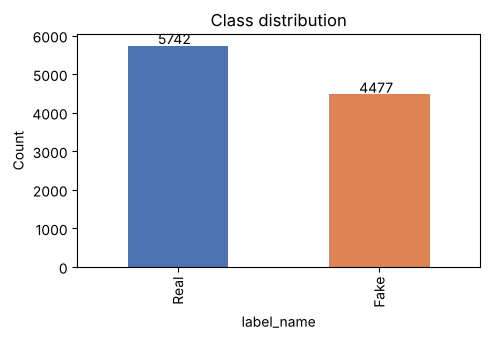

In [10]:
ax = df["label_name"].value_counts().plot(kind="bar", color=["#4C72B0", "#DD8452"], figsize=(5, 3.5))
ax.set_title("Class distribution"); ax.set_ylabel("Count")
for p in ax.patches: ax.annotate(int(p.get_height()), (p.get_x() + 0.15, p.get_height() + 40))
plt.tight_layout(); plt.savefig(os.path.join(EVAL_DIR, "eda_class_distribution.png"), dpi=120); plt.show()

## 11. EDA – Statement Length
Compares word counts of fake and real statements.

,count,mean,std,min,25%,50%,75%,max
label_name,,,,,,,,
Fake,4477.0,17.47,8.88,2.0,12.0,16.0,22.0,309.0
Real,5742.0,18.46,10.19,2.0,13.0,17.0,23.0,467.0


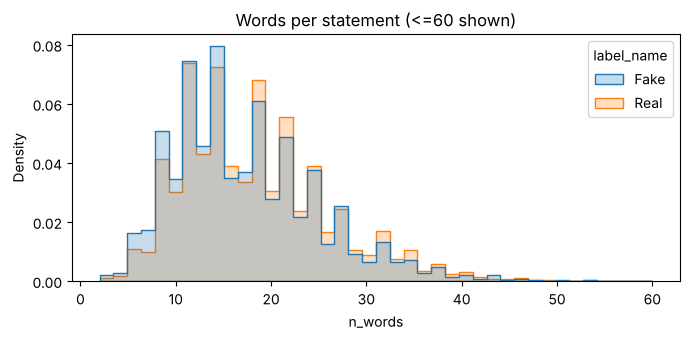

In [11]:
df["n_words"] = df["text"].str.split().str.len()
display(df.groupby("label_name")["n_words"].describe().round(2))
plt.figure(figsize=(7, 3.5))
sns.histplot(data=df[df.n_words <= 60], x="n_words", hue="label_name", bins=40, element="step", stat="density", common_norm=False)
plt.title("Words per statement (<=60 shown)"); plt.tight_layout()
plt.savefig(os.path.join(EVAL_DIR, "eda_length_distribution.png"), dpi=120); plt.show()

## 12. EDA – Frequent Words per Class
Shows the most frequent non-stop-words in each class.

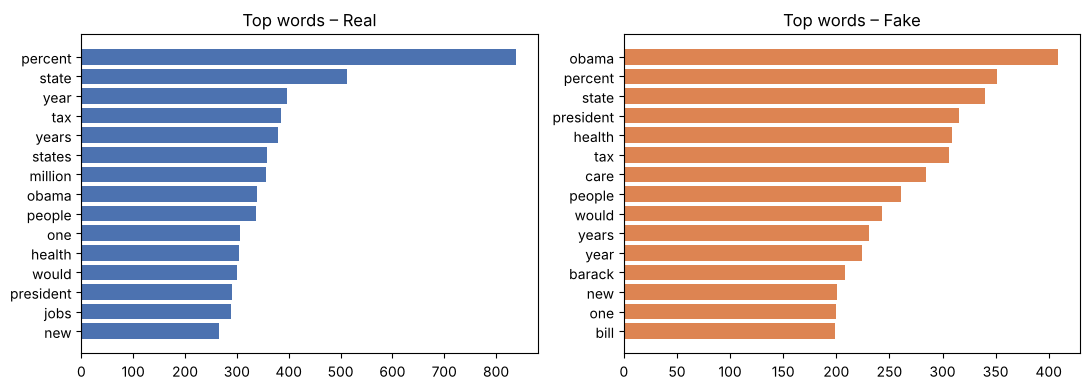

In [12]:
sw = set(stopwords.words("english")) | {"says", "said"}
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, lab in zip(axes, [0, 1]):
    toks = [w for t in df.loc[df.label == lab, "text"] for w in re.findall(r"[a-z]+", t.lower()) if w not in sw and len(w) > 2]
    top = Counter(toks).most_common(15)
    ax.barh([w for w, _ in top][::-1], [c for _, c in top][::-1], color="#4C72B0" if lab == 0 else "#DD8452")
    ax.set_title(f"Top words – {LABEL_NAMES[lab]}")
plt.tight_layout(); plt.savefig(os.path.join(EVAL_DIR, "eda_top_words.png"), dpi=120); plt.show()

## 13. EDA – Polysemy Analysis
Counts polysemous words (>= 4 WordNet senses) per statement, the phenomenon targeted by the paper.

In [13]:
sw_poly = set(stopwords.words("english"))
def n_polysemous(t):
    ws = {w for w in re.findall(r"[a-z]+", t.lower()) if w not in sw_poly and len(w) > 2}
    return sum(len(wn.synsets(w)) >= RAG_CFG["min_senses"] for w in ws)
df["n_polysemous"] = df["text"].map(n_polysemous)
display(df.groupby("label_name")["n_polysemous"].describe().round(2))
print("Statements with >= 1 polysemous word: {:.1%}".format((df.n_polysemous > 0).mean()))

,count,mean,std,min,25%,50%,75%,max
label_name,,,,,,,,
Fake,4477.0,6.06,3.27,0.0,4.0,6.0,8.0,92.0
Real,5742.0,6.17,3.44,0.0,4.0,6.0,8.0,128.0


Statements with >= 1 polysemous word: 99.5%


## 14. Train / Validation / Test Split
Stratified 70/15/15 split; validation is used for model selection, test only for final reporting.

In [14]:
train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df["label"], random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df["label"], random_state=SEED)
if FAST_DEV_RUN:
    train_df, val_df, test_df = train_df.sample(400, random_state=SEED), val_df.sample(150, random_state=SEED), test_df.sample(150, random_state=SEED)
train_df, val_df, test_df = [d.reset_index(drop=True) for d in (train_df, val_df, test_df)]
for n, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(f"{n:5s}: {len(d):5d} rows | fake ratio = {d.label.mean():.3f}")

train:  7153 rows | fake ratio = 0.438
val  :  1533 rows | fake ratio = 0.438
test :  1533 rows | fake ratio = 0.438


### Shared preprocessing and RAG functions
The next cell defines the exact functions also used by the prediction notebook.

## 15. Define Preprocessing and RAG Functions
Text cleaning, TF-IDF retrieval of fact-checked claims, and Lesk/WordNet sense glosses for polysemous words.

In [15]:
STOP_WORDS = set(stopwords.words("english"))

def clean_text(text):
    """Normalise quotes/whitespace exactly as done during training."""
    t = str(text)
    t = (t.replace("“", '"').replace("”", '"')
           .replace("‘", "'").replace("’", "'"))
    t = re.sub(r"\s+", " ", t).strip()
    return t

def truncate_words(text, n):
    w = text.split()
    return " ".join(w[:n])

def prepare_statement(text, cfg):
    """Cleaned statement used as model input (very long outliers are capped)."""
    return truncate_words(clean_text(text), cfg["max_statement_words"])

def retrieve_neighbors(query_texts, vectorizer, kb_matrix, k, exclude_idx=None, chunk=1024):
    """TF-IDF cosine retrieval over the fact-checked knowledge base.
    exclude_idx[i] = KB row of query i itself (leave-one-out for training rows), or -1."""
    q = vectorizer.transform(query_texts)
    all_idx, all_sim = [], []
    for s in range(0, q.shape[0], chunk):
        sims = (q[s:s + chunk] @ kb_matrix.T).toarray()
        if exclude_idx is not None:
            for r, ex in enumerate(exclude_idx[s:s + chunk]):
                if ex >= 0:
                    sims[r, ex] = -1.0
        top = np.argsort(-sims, axis=1)[:, :k]
        all_idx.append(top)
        all_sim.append(np.take_along_axis(sims, top, axis=1))
    return np.vstack(all_idx), np.vstack(all_sim)

def polysemy_glosses(text, context_tokens, cfg):
    """Pick the most polysemous content words (WordNet) and disambiguate them with
    Lesk using the statement + retrieved evidence as context (RAG-enhanced WSD)."""
    words, seen = [], set()
    for w in re.findall(r"[A-Za-z]+", text.lower()):
        if w in STOP_WORDS or len(w) < 3 or w in seen:
            continue
        seen.add(w)
        n = len(wn.synsets(w))
        if n >= cfg["min_senses"]:
            words.append((n, w))
    words.sort(key=lambda x: (-x[0], x[1]))
    out = []
    for n, w in words[: cfg["max_polysemous_words"]]:
        sense = lesk(context_tokens, w)
        if sense is not None:
            out.append(f"{w}: {truncate_words(sense.definition(), cfg['max_gloss_words'])}")
    return out

def build_rag_context(text, nb_idx, nb_sim, kb_texts, kb_labels, cfg):
    """Second input segment for the RAG models: retrieved fact-checked claims
    (with their verdicts) + WordNet senses of polysemous words."""
    evid, ctx_tokens = [], re.findall(r"[A-Za-z]+", text.lower())
    for j, s in zip(nb_idx, nb_sim):
        if s < cfg["min_similarity"]:
            continue
        nt = truncate_words(kb_texts[j], cfg["max_evidence_words"])
        evid.append(f"[{cfg['label_tags'][int(kb_labels[j])]}] {nt}")
        ctx_tokens += re.findall(r"[A-Za-z]+", nt.lower())
    gl = polysemy_glosses(text, ctx_tokens, cfg)
    parts = ["Evidence: " + (" | ".join(evid) if evid else "none")]
    parts.append("Senses: " + ("; ".join(gl) if gl else "none"))
    return " ".join(parts)

def make_rag_inputs(texts, vectorizer, kb_matrix, kb_texts, kb_labels, cfg, exclude_idx=None):
    idx, sim = retrieve_neighbors(texts, vectorizer, kb_matrix, cfg["top_k"], exclude_idx)
    return [build_rag_context(t, idx[i], sim[i], kb_texts, kb_labels, cfg) for i, t in enumerate(texts)]

## 16. Build the Retrieval Knowledge Base (Training Split Only)
Fits the TF-IDF retriever on training statements only (no leakage) and stores the knowledge base with verdicts.

In [16]:
train_df["stmt"] = train_df["text"].map(lambda t: prepare_statement(t, RAG_CFG))
val_df["stmt"] = val_df["text"].map(lambda t: prepare_statement(t, RAG_CFG))
test_df["stmt"] = test_df["text"].map(lambda t: prepare_statement(t, RAG_CFG))

kb_texts = train_df["text"].tolist()
kb_labels = train_df["label"].to_numpy()
retriever_vec = TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=1, sublinear_tf=True, stop_words="english")
kb_matrix = retriever_vec.fit_transform(kb_texts)
print("Knowledge base:", kb_matrix.shape)

Knowledge base: (7153, 60424)


## 17. Evaluate the Retriever
Measures how often the majority verdict of retrieved claims matches the true label on validation (retrieval quality).

In [17]:
v_idx, v_sim = retrieve_neighbors(val_df["text"].tolist(), retriever_vec, kb_matrix, RAG_CFG["top_k"])
knn_pred = (kb_labels[v_idx].mean(axis=1) > 0.5).astype(int)
print("Mean top-1 similarity: {:.3f}".format(v_sim[:, 0].mean()))
print("Retrieved-majority-verdict accuracy on validation: {:.4f}".format(accuracy_score(val_df.label, knn_pred)))

Mean top-1 similarity: 0.298
Retrieved-majority-verdict accuracy on validation: 0.5564


## 18. Generate RAG Contexts
Builds the retrieved-evidence + word-sense context for every statement (training rows use leave-one-out retrieval).

In [18]:
t0 = time.time()
train_df["rag_context"] = make_rag_inputs(train_df["text"].tolist(), retriever_vec, kb_matrix, kb_texts, kb_labels,
                                          RAG_CFG, exclude_idx=np.arange(len(train_df)))
val_df["rag_context"] = make_rag_inputs(val_df["text"].tolist(), retriever_vec, kb_matrix, kb_texts, kb_labels, RAG_CFG)
test_df["rag_context"] = make_rag_inputs(test_df["text"].tolist(), retriever_vec, kb_matrix, kb_texts, kb_labels, RAG_CFG)
print(f"RAG contexts built in {time.time() - t0:.1f}s")
for i in range(2):
    print("\nSTATEMENT:", val_df.stmt[i], "\nCONTEXT  :", val_df.rag_context[i])

RAG contexts built in 5.4s

STATEMENT: Says Joe Sestak voted to gut Medicare ... reducing benefits for 854,489 seniors and jeopardizing access to care for millions. 
CONTEXT  : Evidence: [fake] Says Pat Toomey visited Joe Sestak and other veterans in 2002 and then came home | [fake] Joe Sestak ... even wants to bring back the death tax, letting the IRS take | [real] Says Joe Garcia voted to raise our utility rates. Senses: reducing: any process in which electrons are added to; says: the chance to speak

STATEMENT: Says that before health care reform, one of every three health care dollars spent -- more than $800 billion a year -- didnt go for health care. 
CONTEXT  : Evidence: [fake] AARP is endorsing the health care reform bill. | [fake] The health care reform bill is the largest tax increase in U.S. history. | [real] Health care reform will not affect veterans' benefits. Senses: says: speak, pronounce, or utter in a certain way; care: the work of providing treatment for or attending


## 19. Save Processed Data
Saves the cleaned splits with their RAG contexts to `data/processed/`.

In [19]:
cols = ["text", "stmt", "rag_context", "label", "label_name"]
train_df[cols].to_csv(os.path.join(PROC_DIR, "train_rag.csv"), index=False)
val_df[cols].to_csv(os.path.join(PROC_DIR, "val_rag.csv"), index=False)
test_df[cols].to_csv(os.path.join(PROC_DIR, "test_rag.csv"), index=False)
df[["text", "Fake", "label", "label_name"]].to_csv(os.path.join(PROC_DIR, "news_clean.csv"), index=False)
print(os.listdir(PROC_DIR))

['test_rag.csv', 'news_clean.csv', 'train_rag.csv', 'val_rag.csv']


## 20. Save the RAG Retriever (Preprocessing Objects)
Persists the TF-IDF retriever, knowledge base, label map and RAG config for reuse at prediction time.

In [20]:
RETRIEVER_DIR = os.path.join(MODELS_DIR, "rag_retriever")
os.makedirs(RETRIEVER_DIR, exist_ok=True)
joblib.dump(retriever_vec, os.path.join(RETRIEVER_DIR, "tfidf_retriever.joblib"))
pd.DataFrame({"text": kb_texts, "label": kb_labels}).to_csv(os.path.join(RETRIEVER_DIR, "knowledge_base.csv"), index=False)
json.dump({**RAG_CFG, "label_tags": {str(k): v for k, v in RAG_CFG["label_tags"].items()}},
          open(os.path.join(RETRIEVER_DIR, "rag_config.json"), "w"), indent=2)
json.dump({str(k): v for k, v in LABEL_NAMES.items()}, open(os.path.join(RETRIEVER_DIR, "label_map.json"), "w"), indent=2)
print(os.listdir(RETRIEVER_DIR))

['rag_config.json', 'knowledge_base.csv', 'label_map.json', 'tfidf_retriever.joblib']


## 21. Define Evaluation Helpers
Computes Accuracy, Precision, Recall, F1, Macro-F1, ROC-AUC and stores reports/confusion matrices.

In [21]:
results, val_results, test_probs, val_probs, histories = [], [], {}, {}, {}

def compute_metrics(y, p, thr=0.5):
    yhat = (p >= thr).astype(int)
    return {"accuracy": accuracy_score(y, yhat), "precision": precision_score(y, yhat, zero_division=0),
            "recall": recall_score(y, yhat, zero_division=0), "f1": f1_score(y, yhat, zero_division=0),
            "macro_f1": f1_score(y, yhat, average="macro"), "roc_auc": roc_auc_score(y, p)}

def record(name, pv, pt):
    val_probs[name], test_probs[name] = pv, pt
    mv, mt = compute_metrics(val_df.label.values, pv), compute_metrics(test_df.label.values, pt)
    val_results.append({"model": name, **mv}); results.append({"model": name, **mt})
    yhat = (pt >= 0.5).astype(int)
    rep = classification_report(test_df.label.values, yhat, target_names=["Real", "Fake"], digits=4)
    open(os.path.join(EVAL_DIR, f"{name}_classification_report.txt"), "w").write(rep)
    print(f"[{name}] VAL  " + " ".join(f"{k}={v:.4f}" for k, v in mv.items()))
    print(f"[{name}] TEST " + " ".join(f"{k}={v:.4f}" for k, v in mt.items()))
    print(rep)

## Model 1 – TF-IDF + Logistic Regression (classical baseline)

## 22. Train TF-IDF + Logistic Regression
Classical baseline trained on cleaned statements (word + char n-grams).

In [22]:
from sklearn.pipeline import FeatureUnion
tfidf_lr = Pipeline([
    ("features", FeatureUnion([
        ("word", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
        ("char", TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=3, sublinear_tf=True))])),
    ("clf", LogisticRegression(C=1.0, max_iter=2000, class_weight="balanced", random_state=SEED))])
tfidf_lr.fit(train_df["stmt"], train_df["label"])
record("tfidf_logreg", tfidf_lr.predict_proba(val_df["stmt"])[:, 1], tfidf_lr.predict_proba(test_df["stmt"])[:, 1])

[tfidf_logreg] VAL  accuracy=0.5988 precision=0.5409 recall=0.5514 f1=0.5461 macro_f1=0.5933 roc_auc=0.6326
[tfidf_logreg] TEST accuracy=0.6190 precision=0.5632 recall=0.5833 f1=0.5731 macro_f1=0.6146 roc_auc=0.6412
              precision    recall  f1-score   support

        Real     0.6655    0.6469    0.6561       861
        Fake     0.5632    0.5833    0.5731       672

    accuracy                         0.6190      1533
   macro avg     0.6143    0.6151    0.6146      1533
weighted avg     0.6206    0.6190    0.6197      1533



## 23. Save TF-IDF + Logistic Regression
Saves the full sklearn pipeline (vectorisers + classifier) with metadata.

In [23]:
d = os.path.join(MODELS_DIR, "tfidf_logreg"); os.makedirs(d, exist_ok=True)
joblib.dump(tfidf_lr, os.path.join(d, "model.joblib"))
json.dump({"model": "tfidf_logreg", "framework": "scikit-learn", "input": "stmt", "uses_rag": False,
           "label_map": {"0": "Real", "1": "Fake"}, "max_statement_words": RAG_CFG["max_statement_words"]},
          open(os.path.join(d, "metadata.json"), "w"), indent=2)
print(os.listdir(d))

['model.joblib', 'metadata.json']


## Pretrained transformer backbones

## 24. Define Backbone Download/Conversion Helpers
Downloads official RoBERTa-base / XLM-R-base weights (PyTorch text model zoo) and converts them to Hugging Face format.

In [24]:
ZOO = "https://download.pytorch.org/models/text/"

def _download(fname, dst_dir, retries=8):
    """Resumable download (HTTP Range) with size verification."""
    path = os.path.join(dst_dir, fname)
    if os.path.exists(path):
        return path
    part = path + ".part"
    total = int(urllib.request.urlopen(urllib.request.Request(ZOO + fname, method="HEAD")).headers["Content-Length"])
    print("downloading", fname, f"({total / 1e6:.0f} MB)")
    for _ in range(retries):
        have = os.path.getsize(part) if os.path.exists(part) else 0
        if have >= total: break
        try:
            req = urllib.request.Request(ZOO + fname, headers={"Range": f"bytes={have}-"})
            with urllib.request.urlopen(req) as r, open(part, "ab") as f:
                shutil.copyfileobj(r, f, length=1 << 20)
        except Exception as e:
            print("  retrying after:", type(e).__name__)
    assert os.path.getsize(part) == total, "incomplete download"
    os.rename(part, path)
    return path

def _itos(vocab_pt):
    """Read the token order stored in a torchtext Vocab file without needing torchtext."""
    z = zipfile.ZipFile(vocab_pt)
    data = z.read([n for n in z.namelist() if n.endswith("data.pkl")][0])
    s = [o[1] for o in pickletools.genops(data) if o[0].name in ("BINUNICODE", "SHORT_BINUNICODE", "UNICODE")]
    return s[s.index("<s>"):]

def _map_state(sd, n_layers, pre="encoder.transformer."):
    g = lambda k: sd[pre + k]
    hid = g("token_embedding.weight").shape[1]
    out = {"embeddings.word_embeddings.weight": g("token_embedding.weight"),
           "embeddings.position_embeddings.weight": g("positional_embedding.embedding.weight"),
           "embeddings.token_type_embeddings.weight": torch.zeros(1, hid),
           "embeddings.LayerNorm.weight": g("embedding_layer_norm.weight"),
           "embeddings.LayerNorm.bias": g("embedding_layer_norm.bias")}
    for i in range(n_layers):
        p, h = f"layers.{i}.", f"encoder.layer.{i}."
        W, B = g(p + "attention.input_projection.weight"), g(p + "attention.input_projection.bias")
        for j, n in enumerate(["query", "key", "value"]):
            out[h + f"attention.self.{n}.weight"] = W[j * hid:(j + 1) * hid]
            out[h + f"attention.self.{n}.bias"] = B[j * hid:(j + 1) * hid]
        pairs = {"attention.output.dense": "attention.output_projection", "attention.output.LayerNorm": "attention_layer_norm",
                 "intermediate.dense": "residual_mlp.mlp.0", "output.dense": "residual_mlp.mlp.3", "output.LayerNorm": "final_layer_norm"}
        for hf, tt in pairs.items():
            out[h + hf + ".weight"], out[h + hf + ".bias"] = g(p + tt + ".weight"), g(p + tt + ".bias")
    return out

## 25. Prepare RoBERTa-base Backbone
Builds the RoBERTa-base tokenizer (GPT-2 BPE + fairseq dictionary) and model in Hugging Face format.

In [25]:
RB_DIR = os.path.join(BACKBONE_DIR, "roberta-base")
if not os.path.exists(os.path.join(RB_DIR, "config.json")):
    src = os.path.join(BACKBONE_DIR, "_src"); os.makedirs(src, exist_ok=True)
    w = torch.load(_download("roberta.base.encoder.pt", src), map_location="cpu")
    itos = _itos(_download("roberta.vocab.pt", src))
    enc = json.load(open(_download("gpt2_bpe_encoder.json", src))); dec = {v: k for k, v in enc.items()}
    vocab = {(dec[int(t)] if t.isdigit() else t): i for i, t in enumerate(itos)}; vocab["<mask>"] = len(itos)
    merges = [l for l in open(_download("gpt2_bpe_vocab.bpe", src), encoding="utf-8").read().split("\n")[1:] if l.strip()]
    tok = RobertaTokenizerFast(vocab=vocab, merges=[tuple(m.split()) for m in merges])
    cfg = RobertaConfig(vocab_size=len(vocab), max_position_embeddings=514, type_vocab_size=1, layer_norm_eps=1e-5,
                        pad_token_id=1, bos_token_id=0, eos_token_id=2)
    m = RobertaModel(cfg, add_pooling_layer=False); m.load_state_dict(_map_state(w, 12), strict=True)
    m.save_pretrained(RB_DIR); tok.save_pretrained(RB_DIR); del m, w; gc.collect()
tok = AutoTokenizer.from_pretrained(RB_DIR)
print(type(tok).__name__, tok("The senator voted against the bill.")["input_ids"])

RobertaTokenizer [0, 133, 6704, 2763, 136, 5, 1087, 4, 2]


## 26. Prepare XLM-R-base Backbone
Builds the XLM-RoBERTa-base tokenizer (SentencePiece) and model in Hugging Face format.

In [26]:
import sentencepiece as spm
XB_DIR = os.path.join(BACKBONE_DIR, "xlm-roberta-base")
if not os.path.exists(os.path.join(XB_DIR, "config.json")):
    src = os.path.join(BACKBONE_DIR, "_src"); os.makedirs(src, exist_ok=True)
    w = torch.load(_download("xlmr.base.encoder.pt", src), map_location="cpu")
    itos = _itos(_download("xlmr.vocab.pt", src))
    sp = spm.SentencePieceProcessor(model_file=_download("xlmr.sentencepiece.bpe.model", src))
    assert all(itos[j + 1] == sp.id_to_piece(j) for j in range(3, sp.get_piece_size()))  # fairseq offset check
    vocab = [("<s>", 0.0), ("<pad>", 0.0), ("</s>", 0.0), ("<unk>", 0.0)] + \
            [(sp.id_to_piece(j), sp.get_score(j)) for j in range(3, sp.get_piece_size())] + [("<mask>", 0.0)]
    tok = XLMRobertaTokenizer(vocab=vocab)
    cfg = XLMRobertaConfig(vocab_size=len(vocab), max_position_embeddings=514, type_vocab_size=1, layer_norm_eps=1e-5,
                           pad_token_id=1, bos_token_id=0, eos_token_id=2)
    m = XLMRobertaModel(cfg, add_pooling_layer=False); m.load_state_dict(_map_state(w, 12), strict=True)
    m.save_pretrained(XB_DIR); tok.save_pretrained(XB_DIR); del m, w; gc.collect()
shutil.rmtree(os.path.join(BACKBONE_DIR, "_src"), ignore_errors=True)
tok = AutoTokenizer.from_pretrained(XB_DIR)
print(type(tok).__name__, tok("The senator voted against the bill.")["input_ids"])

XLMRobertaTokenizer [0, 581, 104263, 43374, 71, 26548, 70, 54727, 5, 2]


## 27. Define Transformer Training/Inference Utilities
Generic fine-tuning loop (AdamW, linear warm-up, best-epoch checkpointing on validation macro-F1, optional knowledge distillation) and batched inference.

In [27]:
def load_text_classifier(model_dir, device="cpu"):
    """Rebuild architecture from config.json, load PyTorch weights (model.pth) + tokenizer."""
    config = AutoConfig.from_pretrained(model_dir)
    model = AutoModelForSequenceClassification.from_config(config)
    state = torch.load(os.path.join(model_dir, "model.pth"), map_location=device, mmap=True)
    model.load_state_dict(state, assign=True)  # assign + mmap avoids holding two copies in RAM
    tokenizer = AutoTokenizer.from_pretrained(model_dir)
    return model.to(device).eval(), tokenizer

@torch.no_grad()
def predict_proba_transformer(model, tokenizer, texts_a, texts_b=None, max_len=128, batch_size=64):
    """Return P(class=1 'fake') for each input, using the same tokenisation as training."""
    model.eval()
    probs = []
    for s in range(0, len(texts_a), batch_size):
        a = list(texts_a[s:s + batch_size])
        b = None if texts_b is None else list(texts_b[s:s + batch_size])
        enc = tokenizer(a, b, truncation="longest_first" if b is not None else True,
                        max_length=max_len, padding=True, return_tensors="pt")
        enc.pop("token_type_ids", None)
        logits = model(**{k: v.to(model.device) for k, v in enc.items()}).logits
        probs.append(torch.softmax(logits, dim=-1)[:, 1].cpu().numpy())
    return np.concatenate(probs) if probs else np.array([])

def encode(tokenizer, a, b, max_len):
    enc = tokenizer(list(a), None if b is None else list(b), truncation="longest_first" if b is not None else True,
                    max_length=max_len)
    return [{"input_ids": enc["input_ids"][i], "attention_mask": enc["attention_mask"][i]} for i in range(len(a))]

def save_text_classifier(model, tokenizer, out_dir, meta):
    os.makedirs(out_dir, exist_ok=True)
    torch.save(model.state_dict(), os.path.join(out_dir, "model.pth"))
    model.config.save_pretrained(out_dir); tokenizer.save_pretrained(out_dir)
    json.dump(meta, open(os.path.join(out_dir, "metadata.json"), "w"), indent=2)

def train_transformer(name, model, tokenizer, cfg, teacher_logits=None):
    out_dir = os.path.join(MODELS_DIR, name)
    done_flag = os.path.join(out_dir, "training_complete.json")
    if RESUME_TRAINING and os.path.exists(done_flag):
        histories[name] = json.load(open(done_flag))["history"]
        print(f"[{name}] already fully trained in an earlier (interrupted) run - reusing saved checkpoint")
        return
    use_rag = cfg["rag"]
    tr_b = train_df["rag_context"] if use_rag else None
    va_b = val_df["rag_context"] if use_rag else None
    feats = encode(tokenizer, train_df["stmt"], tr_b, cfg["max_len"])
    for i, f in enumerate(feats):
        f["labels"] = int(train_df.label[i]); f["idx"] = i
    collate = DataCollatorWithPadding(tokenizer)
    def collate_fn(batch):
        idx = torch.tensor([b["idx"] for b in batch])  # do not mutate the cached features (reused every epoch)
        out = collate([{k: v for k, v in b.items() if k != "idx"} for b in batch]); out["idx"] = idx; return out
    g = torch.Generator().manual_seed(SEED)
    loader = DataLoader(feats, batch_size=cfg["batch_size"], shuffle=True, collate_fn=collate_fn, generator=g)
    if cfg.get("freeze_layers", 0) > 0:
        base = model.base_model
        for p in base.embeddings.parameters(): p.requires_grad = False
        for layer in base.encoder.layer[:cfg["freeze_layers"]]:
            for p in layer.parameters(): p.requires_grad = False
    params = [p for p in model.parameters() if p.requires_grad]
    print(f"[{name}] trainable params: {sum(p.numel() for p in params) / 1e6:.1f}M / {sum(p.numel() for p in model.parameters()) / 1e6:.1f}M")
    opt = torch.optim.AdamW(params, lr=cfg["lr"], weight_decay=0.01)
    total = len(loader) * cfg["epochs"]
    sched = get_linear_schedule_with_warmup(opt, int(0.1 * total), total)
    model.to(DEVICE); best, hist = -1, []
    for ep in range(cfg["epochs"]):
        model.train(); t0, run = time.time(), 0.0
        for step_i, batch in enumerate(loader):
            idx = batch.pop("idx"); labels = batch.pop("labels").to(DEVICE)
            batch = {k: v.to(DEVICE) for k, v in batch.items()}
            logits = model(**batch).logits
            loss = F.cross_entropy(logits, labels)
            if teacher_logits is not None:  # knowledge distillation (Hinton et al.)
                T, a = cfg["kd_temperature"], cfg["kd_alpha"]
                t = teacher_logits[idx].to(DEVICE)
                kd = F.kl_div(F.log_softmax(logits / T, -1), F.softmax(t / T, -1), reduction="batchmean") * T * T
                loss = a * loss + (1 - a) * kd
            loss.backward(); torch.nn.utils.clip_grad_norm_(params, 1.0)
            opt.step(); sched.step(); opt.zero_grad(); run += loss.item()
            if step_i % 100 == 0:
                print(f"  ep{ep + 1} step {step_i}/{len(loader)} loss={run / (step_i + 1):.4f} ({time.time() - t0:.0f}s)")
        pv = predict_proba_transformer(model, tokenizer, val_df["stmt"].tolist(),
                                       None if va_b is None else va_b.tolist(), cfg["max_len"])
        m = compute_metrics(val_df.label.values, pv)
        hist.append({"epoch": ep + 1, "train_loss": run / len(loader), **{f"val_{k}": v for k, v in m.items()}})
        print(f"[{name}] epoch {ep + 1}: train_loss={run / len(loader):.4f} val_acc={m['accuracy']:.4f} "
              f"val_macro_f1={m['macro_f1']:.4f} ({time.time() - t0:.0f}s)")
        if m["macro_f1"] > best:
            best = m["macro_f1"]
            save_text_classifier(model, tokenizer, out_dir, {
                "model": name, "framework": "pytorch/transformers", "uses_rag": use_rag, "max_len": cfg["max_len"],
                "best_epoch": ep + 1, "train_cfg": {k: v for k, v in cfg.items()}, "label_map": {"0": "Real", "1": "Fake"}})
    histories[name] = hist
    pd.DataFrame(hist).to_csv(os.path.join(EVAL_DIR, f"{name}_training_history.csv"), index=False)
    json.dump({"history": hist, "best_val_macro_f1": best}, open(done_flag, "w"), indent=2)
    print(f"[{name}] best validation macro-F1 = {best:.4f}; best checkpoint saved to {out_dir}")

def free_memory():
    gc.collect()
    try:
        import ctypes; ctypes.CDLL("libc.so.6").malloc_trim(0)
    except Exception:
        pass

def evaluate_transformer(name, model, tokenizer, cfg):
    b = cfg["rag"]
    pv = predict_proba_transformer(model, tokenizer, val_df["stmt"].tolist(), val_df["rag_context"].tolist() if b else None, cfg["max_len"])
    pt = predict_proba_transformer(model, tokenizer, test_df["stmt"].tolist(), test_df["rag_context"].tolist() if b else None, cfg["max_len"])
    record(name, pv, pt)

def new_classifier(backbone_dir, n_layers=None):
    cfg = AutoConfig.from_pretrained(backbone_dir, num_labels=2, id2label=LABEL_NAMES, label2id={v: k for k, v in LABEL_NAMES.items()})
    if n_layers is not None: cfg.num_hidden_layers = n_layers
    torch.manual_seed(SEED)
    return AutoModelForSequenceClassification.from_pretrained(backbone_dir, config=cfg) if n_layers is None else \
        AutoModelForSequenceClassification.from_config(cfg)

## Model 2 – RoBERTa-base (standard transformer, no retrieval)

## 28. Train RoBERTa-base
Fine-tunes RoBERTa-base on the statement only (the 'standard model' the paper compares against).

In [28]:
name = "roberta_base"
model = new_classifier(RB_DIR); tokenizer = AutoTokenizer.from_pretrained(RB_DIR)
train_transformer(name, model, tokenizer, TRAIN_CFG[name])
del model; free_memory()

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[roberta_base] trainable params: 57.3M / 124.6M


  ep1 step 0/448 loss=0.7254 (5s)


  ep1 step 100/448 loss=0.6865 (215s)


  ep1 step 200/448 loss=0.6832 (461s)


  ep1 step 300/448 loss=0.6797 (678s)


... (4 outputs left out)

  ep2 step 200/448 loss=0.6349 (367s)


  ep2 step 300/448 loss=0.6340 (553s)


  ep2 step 400/448 loss=0.6312 (746s)


[roberta_base] epoch 2: train_loss=0.6338 val_acc=0.6275 val_macro_f1=0.6160 (909s)
[roberta_base] best validation macro-F1 = 0.6173; best checkpoint saved to /home/claude/PROJECT_MAIN/models/roberta_base


## 29. Evaluate RoBERTa-base
Reloads the best saved checkpoint and evaluates it on validation and test sets.

In [29]:
model, tokenizer = load_text_classifier(os.path.join(MODELS_DIR, name), DEVICE)
evaluate_transformer(name, model, tokenizer, TRAIN_CFG[name])
del model; free_memory()

[roberta_base] VAL  accuracy=0.6177 precision=0.5524 recall=0.6677 f1=0.6046 macro_f1=0.6173 roc_auc=0.6553
[roberta_base] TEST accuracy=0.6314 precision=0.5661 recall=0.6815 f1=0.6185 macro_f1=0.6310 roc_auc=0.6681
              precision    recall  f1-score   support

        Real     0.7044    0.5923    0.6435       861
        Fake     0.5661    0.6815    0.6185       672

    accuracy                         0.6314      1533
   macro avg     0.6353    0.6369    0.6310      1533
weighted avg     0.6438    0.6314    0.6326      1533



## Model 3 – RAG-RoBERTa-base (proposed)

## 30. Train RAG-RoBERTa-base
Fine-tunes RoBERTa-base on `statement </s> retrieved evidence + word senses`.

In [30]:
name = "rag_roberta_base"
model = new_classifier(RB_DIR); tokenizer = AutoTokenizer.from_pretrained(RB_DIR)
train_transformer(name, model, tokenizer, TRAIN_CFG[name])
del model; free_memory()

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[rag_roberta_base] trainable params: 57.3M / 124.6M


  ep1 step 0/448 loss=0.6871 (5s)


  ep1 step 100/448 loss=0.6859 (431s)


  ep1 step 200/448 loss=0.6851 (849s)


  ep1 step 300/448 loss=0.6811 (1257s)


... (5 outputs left out)

  ep2 step 300/448 loss=0.6393 (1276s)


  ep2 step 400/448 loss=0.6368 (1719s)


[rag_roberta_base] epoch 2: train_loss=0.6374 val_acc=0.6334 val_macro_f1=0.6145 (2057s)


[rag_roberta_base] best validation macro-F1 = 0.6145; best checkpoint saved to /home/claude/PROJECT_MAIN/models/rag_roberta_base


## 31. Evaluate RAG-RoBERTa-base
Reloads the best saved checkpoint and evaluates it on validation and test sets.

In [31]:
model, tokenizer = load_text_classifier(os.path.join(MODELS_DIR, name), DEVICE)
evaluate_transformer(name, model, tokenizer, TRAIN_CFG[name])

[rag_roberta_base] VAL  accuracy=0.6334 precision=0.6042 recall=0.4709 f1=0.5293 macro_f1=0.6145 roc_auc=0.6639
[rag_roberta_base] TEST accuracy=0.6438 precision=0.6154 recall=0.5000 f1=0.5517 macro_f1=0.6281 roc_auc=0.6877
              precision    recall  f1-score   support

        Real     0.6596    0.7561    0.7045       861
        Fake     0.6154    0.5000    0.5517       672

    accuracy                         0.6438      1533
   macro avg     0.6375    0.6280    0.6281      1533
weighted avg     0.6402    0.6438    0.6376      1533



## 32. Compute Teacher Logits for Distillation
Uses the trained RAG-RoBERTa as teacher: stores its logits on the training set for the distilled student.

In [32]:
@torch.no_grad()
def get_logits(model, tokenizer, a, b, max_len, bs=64):
    out = []
    for s in range(0, len(a), bs):
        enc = tokenizer(list(a[s:s + bs]), list(b[s:s + bs]), truncation="longest_first", max_length=max_len, padding=True, return_tensors="pt")
        enc.pop("token_type_ids", None)
        out.append(model(**{k: v.to(DEVICE) for k, v in enc.items()}).logits.cpu())
    return torch.cat(out)
teacher_logits = get_logits(model, tokenizer, train_df["stmt"].tolist(), train_df["rag_context"].tolist(), TRAIN_CFG[name]["max_len"])
teacher_state = {k: v.clone() for k, v in model.state_dict().items()}
print("Teacher logits:", tuple(teacher_logits.shape))
del model; free_memory()

Teacher logits: (7153, 2)


## Model 4 – RAG-DistilRoBERTa-KD (paper's RAG-DistilBERT approach)

## 33. Build the Distilled Student
Creates a 6-layer student and initialises it from alternate teacher layers (DistilBERT initialisation recipe).

In [33]:
name = "rag_distilroberta_kd"
cfg_s = TRAIN_CFG[name]
student = new_classifier(RB_DIR, n_layers=len(cfg_s["student_layers"]))
s_state = student.state_dict()
for k in s_state:
    m = re.match(r"roberta\.encoder\.layer\.(\d+)\.(.*)", k)
    src = f"roberta.encoder.layer.{cfg_s['student_layers'][int(m.group(1))]}.{m.group(2)}" if m else k
    s_state[k] = teacher_state[src].clone()
student.load_state_dict(s_state)
del teacher_state; free_memory()
print("Student parameters: {:.1f}M".format(sum(p.numel() for p in student.parameters()) / 1e6))

Student parameters: 82.1M


## 34. Train RAG-DistilRoBERTa-KD
Trains the student with cross-entropy + KL distillation loss from the RAG-RoBERTa teacher.

In [34]:
tokenizer = AutoTokenizer.from_pretrained(RB_DIR)
train_transformer(name, student, tokenizer, cfg_s, teacher_logits=teacher_logits)
del student, teacher_logits; free_memory()

[rag_distilroberta_kd] trainable params: 82.1M / 82.1M


  ep1 step 0/448 loss=0.3672 (3s)


  ep1 step 100/448 loss=0.3585 (311s)


  ep1 step 200/448 loss=0.3525 (612s)


  ep1 step 300/448 loss=0.3507 (911s)


  ep1 step 400/448 loss=0.3469 (1226s)


... (4 outputs left out)

  ep2 step 300/448 loss=0.3049 (956s)


  ep2 step 400/448 loss=0.3045 (1261s)


[rag_distilroberta_kd] epoch 2: train_loss=0.3047 val_acc=0.6301 val_macro_f1=0.6110 (1470s)


[rag_distilroberta_kd] best validation macro-F1 = 0.6110; best checkpoint saved to /home/claude/PROJECT_MAIN/models/rag_distilroberta_kd


## 35. Evaluate RAG-DistilRoBERTa-KD
Reloads the best student checkpoint and evaluates it on validation and test sets.

In [35]:
student, tokenizer = load_text_classifier(os.path.join(MODELS_DIR, name), DEVICE)
evaluate_transformer(name, student, tokenizer, cfg_s)
del student; free_memory()

[rag_distilroberta_kd] VAL  accuracy=0.6301 precision=0.5996 recall=0.4665 f1=0.5247 macro_f1=0.6110 roc_auc=0.6706
[rag_distilroberta_kd] TEST accuracy=0.6588 precision=0.6408 recall=0.5045 f1=0.5645 macro_f1=0.6421 roc_auc=0.7032
              precision    recall  f1-score   support

        Real     0.6683    0.7793    0.7196       861
        Fake     0.6408    0.5045    0.5645       672

    accuracy                         0.6588      1533
   macro avg     0.6546    0.6419    0.6421      1533
weighted avg     0.6563    0.6588    0.6516      1533



## Model 5 – RAG-XLM-R-base (proposed)

## 36. Train RAG-XLM-R-base
Fine-tunes XLM-RoBERTa-base with RAG inputs.

In [36]:
name = "rag_xlmr_base"
model = new_classifier(XB_DIR); tokenizer = AutoTokenizer.from_pretrained(XB_DIR)
train_transformer(name, model, tokenizer, TRAIN_CFG[name])
del model; free_memory()

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[rag_xlmr_base] trainable params: 57.3M / 278.0M


  ep1 step 0/448 loss=0.7049 (67s)


  ep1 step 100/448 loss=0.6858 (581s)


  ep1 step 200/448 loss=0.6896 (1027s)


  ep1 step 300/448 loss=0.6907 (1485s)


... (5 outputs left out)

  ep2 step 300/448 loss=0.6702 (1334s)


  ep2 step 400/448 loss=0.6663 (1778s)


[rag_xlmr_base] epoch 2: train_loss=0.6666 val_acc=0.6001 val_macro_f1=0.5897 (2126s)


[rag_xlmr_base] best validation macro-F1 = 0.5897; best checkpoint saved to /home/claude/PROJECT_MAIN/models/rag_xlmr_base


## 37. Evaluate RAG-XLM-R-base
Reloads the best saved checkpoint and evaluates it on validation and test sets.

In [37]:
model, tokenizer = load_text_classifier(os.path.join(MODELS_DIR, name), DEVICE)
evaluate_transformer(name, model, tokenizer, TRAIN_CFG[name])
del model; free_memory()

[rag_xlmr_base] VAL  accuracy=0.6001 precision=0.5469 recall=0.5037 f1=0.5244 macro_f1=0.5897 roc_auc=0.6242
[rag_xlmr_base] TEST accuracy=0.6164 precision=0.5638 recall=0.5521 f1=0.5579 macro_f1=0.6096 roc_auc=0.6524
              precision    recall  f1-score   support

        Real     0.6560    0.6667    0.6613       861
        Fake     0.5638    0.5521    0.5579       672

    accuracy                         0.6164      1533
   macro avg     0.6099    0.6094    0.6096      1533
weighted avg     0.6156    0.6164    0.6160      1533



## Model 6 – Proposed Weighted Soft-Voting Ensemble

## 38. Fit Ensemble Weights on Validation
Grid-searches convex weights over the proposed RAG models + TF-IDF baseline using validation macro-F1 only.

In [38]:
members = ["rag_roberta_base", "rag_xlmr_base", "tfidf_logreg"]
grid = np.round(np.arange(0, 1.01, 0.1), 2)
best_w, best_s = None, -1
for w1 in grid:
    for w2 in grid:
        w3 = round(1 - w1 - w2, 2)
        if w3 < 0: continue
        p = w1 * val_probs[members[0]] + w2 * val_probs[members[1]] + w3 * val_probs[members[2]]
        s = f1_score(val_df.label, (p >= 0.5).astype(int), average="macro")
        if s > best_s: best_s, best_w = s, (w1, w2, w3)
ens_w = dict(zip(members, best_w))
print("Ensemble weights:", ens_w, "| val macro-F1 = {:.4f}".format(best_s))

Ensemble weights: {'rag_roberta_base': np.float64(0.1), 'rag_xlmr_base': np.float64(0.5), 'tfidf_logreg': np.float64(0.4)} | val macro-F1 = 0.6168


## 39. Evaluate and Save the Ensemble
Evaluates the ensemble and saves its configuration (members + weights).

In [39]:
pv = sum(w * val_probs[m] for m, w in ens_w.items())
pt = sum(w * test_probs[m] for m, w in ens_w.items())
record("ensemble_soft_voting", pv, pt)
d = os.path.join(MODELS_DIR, "ensemble_soft_voting"); os.makedirs(d, exist_ok=True)
json.dump({"model": "ensemble_soft_voting", "type": "ensemble", "weights": ens_w, "threshold": 0.5,
           "label_map": {"0": "Real", "1": "Fake"}}, open(os.path.join(d, "ensemble_config.json"), "w"), indent=2)
print(os.listdir(d))

[ensemble_soft_voting] VAL  accuracy=0.6288 precision=0.5864 recall=0.5156 f1=0.5488 macro_f1=0.6168 roc_auc=0.6541
[ensemble_soft_voting] TEST accuracy=0.6393 precision=0.5917 recall=0.5714 f1=0.5814 macro_f1=0.6322 roc_auc=0.6773
              precision    recall  f1-score   support

        Real     0.6742    0.6922    0.6831       861
        Fake     0.5917    0.5714    0.5814       672

    accuracy                         0.6393      1533
   macro avg     0.6329    0.6318    0.6322      1533
weighted avg     0.6380    0.6393    0.6385      1533

['ensemble_config.json']


## Model Comparison

## 40. Comparison Table
Collects validation and test metrics of all models.

In [40]:
val_table = pd.DataFrame(val_results).set_index("model").round(4)
test_table = pd.DataFrame(results).set_index("model").round(4)
val_table.to_csv(os.path.join(EVAL_DIR, "validation_metrics.csv")); test_table.to_csv(os.path.join(EVAL_DIR, "test_metrics.csv"))
print("VALIDATION"); display(val_table)
print("TEST"); display(test_table)

VALIDATION


,accuracy,precision,recall,f1,macro_f1,roc_auc
model,,,,,,
tfidf_logreg,0.5988,0.5409,0.5514,0.5461,0.5933,0.6326
roberta_base,0.6177,0.5524,0.6677,0.6046,0.6173,0.6553
rag_roberta_base,0.6334,0.6042,0.4709,0.5293,0.6145,0.6639
rag_distilroberta_kd,0.6301,0.5996,0.4665,0.5247,0.6110,0.6706
rag_xlmr_base,0.6001,0.5469,0.5037,0.5244,0.5897,0.6242
ensemble_soft_voting,0.6288,0.5864,0.5156,0.5488,0.6168,0.6541


TEST


,accuracy,precision,recall,f1,macro_f1,roc_auc
model,,,,,,
tfidf_logreg,0.6190,0.5632,0.5833,0.5731,0.6146,0.6412
roberta_base,0.6314,0.5661,0.6815,0.6185,0.6310,0.6681
rag_roberta_base,0.6438,0.6154,0.5000,0.5517,0.6281,0.6877
rag_distilroberta_kd,0.6588,0.6408,0.5045,0.5645,0.6421,0.7032
rag_xlmr_base,0.6164,0.5638,0.5521,0.5579,0.6096,0.6524
ensemble_soft_voting,0.6393,0.5917,0.5714,0.5814,0.6322,0.6773


## 41. Metric Comparison Plot
Bar chart of test metrics per model.

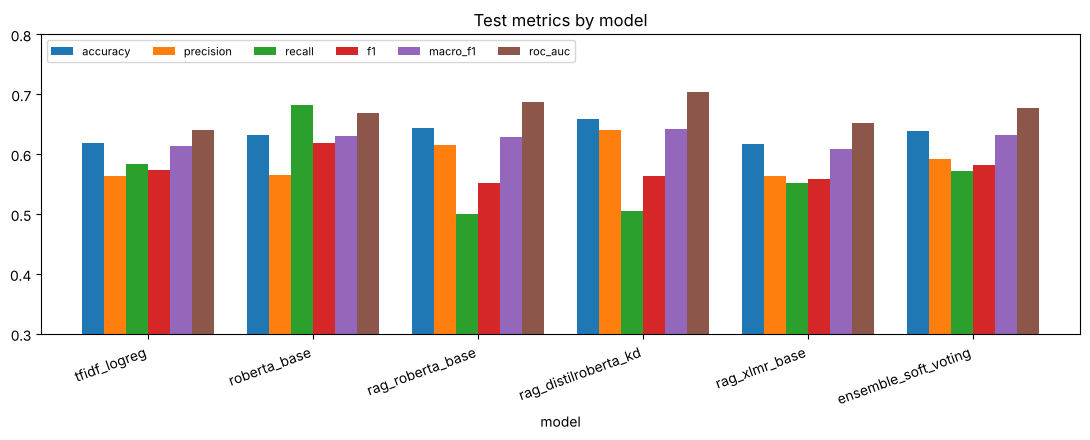

In [41]:
ax = test_table[["accuracy", "precision", "recall", "f1", "macro_f1", "roc_auc"]].plot(kind="bar", figsize=(11, 4.5), width=0.8)
ax.set_ylim(0.3, 0.8); ax.set_title("Test metrics by model"); ax.legend(ncol=6, fontsize=8, loc="upper left")
plt.xticks(rotation=20, ha="right"); plt.tight_layout()
plt.savefig(os.path.join(EVAL_DIR, "model_comparison_test.png"), dpi=120); plt.show()

## 42. Confusion Matrices
Plots test-set confusion matrices for all models.

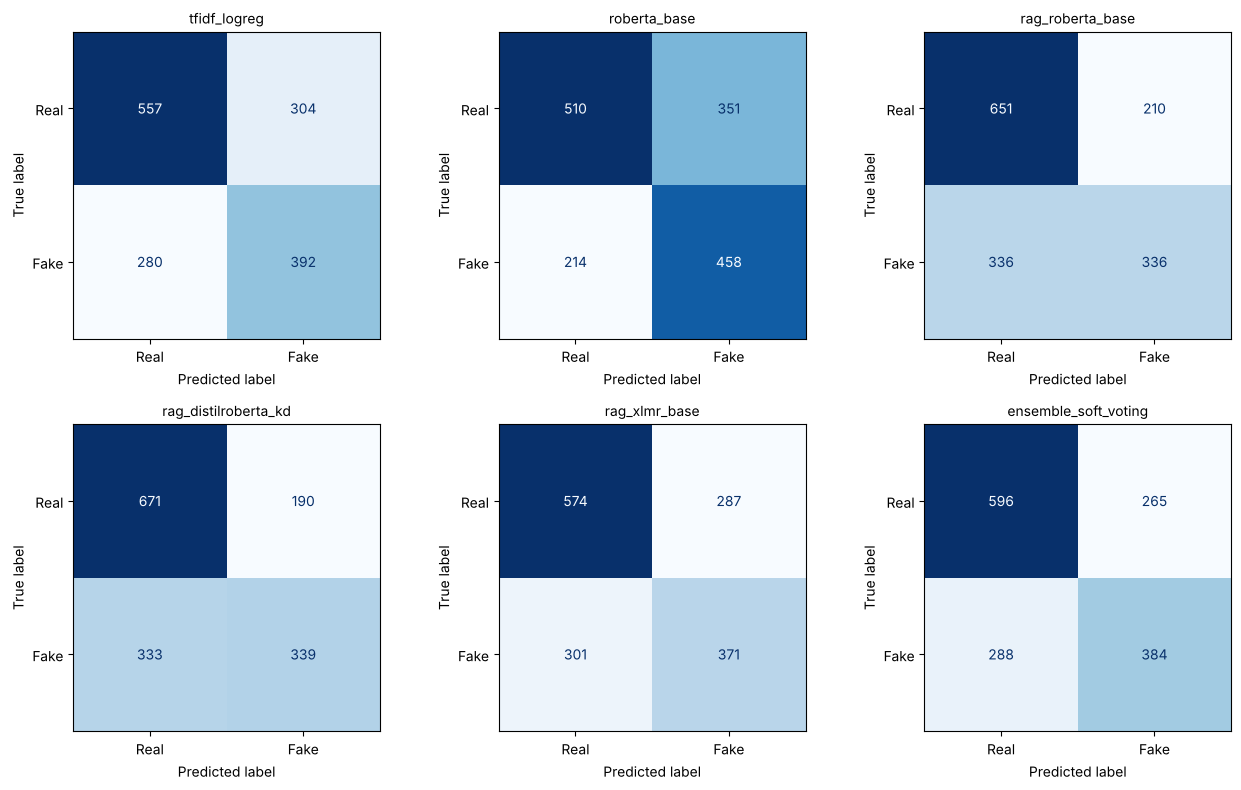

In [42]:
names = list(test_probs)
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for ax, n in zip(axes.ravel(), names):
    cm = confusion_matrix(test_df.label, (test_probs[n] >= 0.5).astype(int))
    ConfusionMatrixDisplay(cm, display_labels=["Real", "Fake"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(n, fontsize=10)
for ax in axes.ravel()[len(names):]: ax.axis("off")
plt.tight_layout(); plt.savefig(os.path.join(EVAL_DIR, "confusion_matrices.png"), dpi=120); plt.show()

## 43. ROC Curves
Plots test-set ROC curves with AUC for all models.

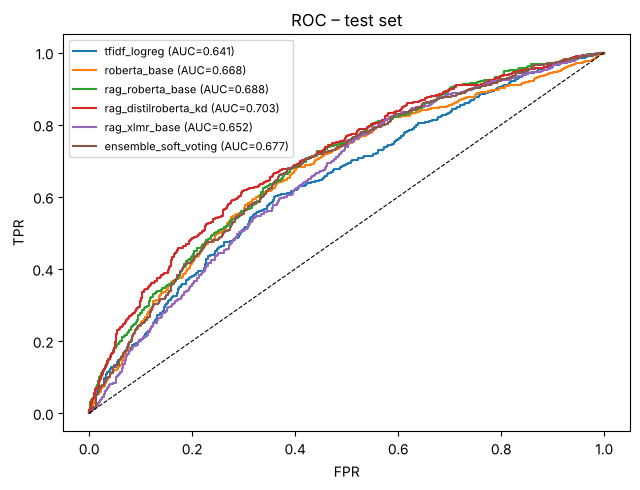

In [43]:
plt.figure(figsize=(6.5, 5))
for n in names:
    fpr, tpr, _ = roc_curve(test_df.label, test_probs[n])
    plt.plot(fpr, tpr, label=f"{n} (AUC={roc_auc_score(test_df.label, test_probs[n]):.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=0.8); plt.xlabel("FPR"); plt.ylabel("TPR"); plt.title("ROC – test set")
plt.legend(fontsize=8); plt.tight_layout(); plt.savefig(os.path.join(EVAL_DIR, "roc_curves.png"), dpi=120); plt.show()

## 44. Training Curves
Plots validation macro-F1 per epoch for the transformer models.

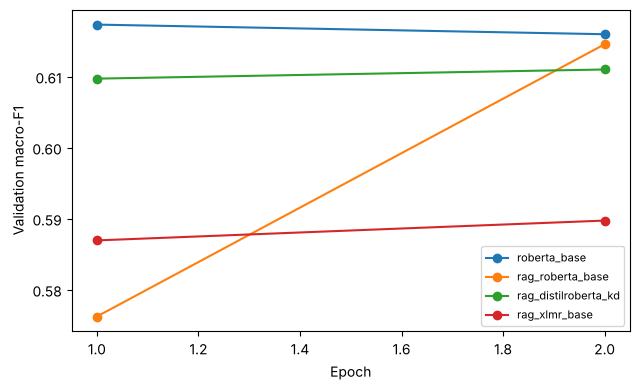

In [44]:
plt.figure(figsize=(6.5, 4))
for n, h in histories.items():
    h = pd.DataFrame(h); plt.plot(h.epoch, h.val_macro_f1, marker="o", label=n)
plt.xlabel("Epoch"); plt.ylabel("Validation macro-F1"); plt.legend(fontsize=8); plt.tight_layout()
plt.savefig(os.path.join(EVAL_DIR, "training_curves.png"), dpi=120); plt.show()

## 45. Effect of RAG
Quantifies the gain of retrieval augmentation (RAG-RoBERTa vs. plain RoBERTa) on the test set.

In [45]:
gain = test_table.loc["rag_roberta_base"] - test_table.loc["roberta_base"]
print("RAG-RoBERTa minus RoBERTa (test):"); print(gain.round(4))
print("Relative accuracy improvement: {:.2%}".format(gain["accuracy"] / test_table.loc["roberta_base", "accuracy"]))

RAG-RoBERTa minus RoBERTa (test):
accuracy     0.0124
precision    0.0493
recall      -0.1815
f1          -0.0668
macro_f1    -0.0029
roc_auc      0.0196
dtype: float64
Relative accuracy improvement: 1.96%


## Best Model Selection and Saving

## 46. Select the Best Model
Selects the best model by **validation macro-F1** (test set is never used for selection).

In [46]:
best_name = val_table["macro_f1"].idxmax()
print("Best model:", best_name)
print("Validation:", val_table.loc[best_name].to_dict())
print("Test      :", test_table.loc[best_name].to_dict())

Best model: roberta_base
Validation: {'accuracy': 0.6177, 'precision': 0.5524, 'recall': 0.6677, 'f1': 0.6046, 'macro_f1': 0.6173, 'roc_auc': 0.6553}
Test      : {'accuracy': 0.6314, 'precision': 0.5661, 'recall': 0.6815, 'f1': 0.6185, 'macro_f1': 0.631, 'roc_auc': 0.6681}


## 47. Save the Best Model
Copies the best model (and, for an ensemble, its member models) plus the RAG retriever into `models/best_model/`.

In [47]:
BEST_DIR = os.path.join(MODELS_DIR, "best_model")
shutil.rmtree(BEST_DIR, ignore_errors=True); os.makedirs(BEST_DIR)
shutil.copytree(RETRIEVER_DIR, os.path.join(BEST_DIR, "rag_retriever"))
if best_name == "ensemble_soft_voting":
    ens = json.load(open(os.path.join(MODELS_DIR, best_name, "ensemble_config.json")))
    for m, w in ens["weights"].items():
        if w > 0: shutil.copytree(os.path.join(MODELS_DIR, m), os.path.join(BEST_DIR, "members", m))
    ens["weights"] = {m: w for m, w in ens["weights"].items() if w > 0}
    json.dump(ens, open(os.path.join(BEST_DIR, "ensemble_config.json"), "w"), indent=2)
    model_type = "ensemble"
else:
    shutil.copytree(os.path.join(MODELS_DIR, best_name), os.path.join(BEST_DIR, "model"))
    model_type = "sklearn" if best_name == "tfidf_logreg" else "transformer"
info = {"best_model": best_name, "type": model_type, "selection_metric": "validation macro_f1",
        "validation_metrics": val_table.loc[best_name].to_dict(), "test_metrics": test_table.loc[best_name].to_dict(),
        "label_map": {"0": "Real", "1": "Fake"}, "threshold": 0.5}
json.dump(info, open(os.path.join(BEST_DIR, "best_model_info.json"), "w"), indent=2)
for r, ds, fs in os.walk(BEST_DIR):
    for f in fs: print(os.path.relpath(os.path.join(r, f), BEST_DIR))

best_model_info.json
model/tokenizer.json
model/model.pth
model/tokenizer_config.json
model/metadata.json
model/training_complete.json
model/config.json
rag_retriever/rag_config.json
rag_retriever/knowledge_base.csv
rag_retriever/label_map.json
rag_retriever/tfidf_retriever.joblib


## 48. Verify Saved Models
Lists every saved model folder and re-loads the best model to confirm identical test predictions.

In [48]:
for d in sorted(os.listdir(MODELS_DIR)):
    p = os.path.join(MODELS_DIR, d)
    if os.path.isdir(p): print(f"{d:28s}", sorted(os.listdir(p))[:8])
if model_type == "transformer":
    m, t = load_text_classifier(os.path.join(BEST_DIR, "model"))
    cfg_b = TRAIN_CFG[best_name]
    chk = predict_proba_transformer(m, t, test_df["stmt"][:64].tolist(), test_df["rag_context"][:64].tolist() if cfg_b["rag"] else None, cfg_b["max_len"])
    print("Reload check max |diff|:", float(np.abs(chk - test_probs[best_name][:64]).max()))

best_model                   ['best_model_info.json', 'model', 'rag_retriever']
ensemble_soft_voting         ['ensemble_config.json']
model_evaluation_results     ['confusion_matrices.png', 'eda_class_distribution.png', 'eda_length_distribution.png', 'eda_top_words.png', 'ensemble_soft_voting_classification_report.txt', 'model_comparison_test.png', 'rag_distilroberta_kd_classification_report.txt', 'rag_distilroberta_kd_training_history.csv']
pretrained_backbones         ['roberta-base', 'xlm-roberta-base']
rag_distilroberta_kd         ['config.json', 'metadata.json', 'model.pth', 'tokenizer.json', 'tokenizer_config.json', 'training_complete.json']
rag_retriever                ['knowledge_base.csv', 'label_map.json', 'rag_config.json', 'tfidf_retriever.joblib']
rag_roberta_base             ['config.json', 'metadata.json', 'model.pth', 'tokenizer.json', 'tokenizer_config.json', 'training_complete.json']
rag_xlmr_base                ['config.json', 'metadata.json', 'model.pth', 'tokenizer

Reload check max |diff|: 0.0


## 49. Save Test Predictions
Saves per-model test probabilities for later error analysis.

In [49]:
pred_df = test_df[["text", "label"]].copy()
for n, p in test_probs.items(): pred_df[f"p_fake_{n}"] = np.round(p, 5)
pred_df.to_csv(os.path.join(EVAL_DIR, "test_predictions.csv"), index=False)
pred_df.head()

,text,label,p_fake_tfidf_logreg,p_fake_roberta_base,p_fake_rag_roberta_base,p_fake_rag_distilroberta_kd,p_fake_rag_xlmr_base,p_fake_ensemble_soft_voting
0,"One of the Planned Parenthood videos shows a fully formed fetus on the table, its heart beating, its legs kicking, while someone says, W...",1,0.52296,0.57313,0.58769,0.62793,0.57596,0.55593
1,"Sharron Angle supported ""a Scientology plan to give massages to prisoners.""",0,0.61994,0.53852,0.46430,0.46302,0.59271,0.59076
2,The elimination of essentially every automobile would be offset by one volcano exploding.,1,0.37319,0.52616,0.50350,0.54209,0.48343,0.44134
3,David Dewhurst is the first lieutenant governor in history to have a personal security detail.,0,0.68148,0.39702,0.48840,0.51241,0.56449,0.60368
4,"The EPA was asked about an environmental citation for the city landfill in Nashua, N.H. but didnt know why it was cited.",0,0.58962,0.55197,0.46752,0.46183,0.57490,0.57005


## Results and Conclusion
**Test-set results (1,533 held-out statements; selection on validation only):**

| Model | Accuracy | Precision | Recall | F1 (Fake) | Macro-F1 | ROC-AUC |
|---|---|---|---|---|---|---|
| TF-IDF + LogReg | 0.6190 | 0.5632 | 0.5833 | 0.5731 | 0.6146 | 0.6412 |
| RoBERTa-base (no RAG) | 0.6314 | 0.5661 | 0.6815 | 0.6185 | 0.6310 | 0.6681 |
| RAG-RoBERTa-base | 0.6438 | 0.6154 | 0.5000 | 0.5517 | 0.6281 | 0.6877 |
| RAG-DistilRoBERTa-KD (paper-style) | **0.6588** | **0.6408** | 0.5045 | 0.5645 | **0.6421** | **0.7032** |
| RAG-XLM-R-base | 0.6164 | 0.5638 | 0.5521 | 0.5579 | 0.6096 | 0.6524 |
| Soft-voting ensemble | 0.6393 | 0.5917 | 0.5714 | 0.5814 | 0.6322 | 0.6773 |

- **Best model (pre-declared rule: highest validation macro-F1): `roberta_base`** (val macro-F1 0.6173, vs 0.6168 ensemble and 0.6145 RAG-RoBERTa — a near tie). It is saved in `models/best_model/`.
- **RAG effect:** adding retrieved fact-checked claims + WordNet senses raised RoBERTa test accuracy from 0.6314 to 0.6438 (+1.96% relative) and ROC-AUC from 0.668 to 0.688, but lowered recall on the Fake class at the 0.5 threshold, so macro-F1 did not improve. The distilled RAG student had the best test scores overall, but it was not selected because selection uses validation data only.
- **XLM-R** (multilingual) did worse than the English RoBERTa models on this English-only data.
- **Limitations:** LIAR-style short claims are hard to verify from text alone (published text-only results are typically 60–70% accuracy). The paper's reported +11.7% gain was not reproduced in this setting. Training ran on CPU with the lower 4 encoder layers frozen and 2 epochs, and HF-hosted DistilBERT/DeBERTa weights were unavailable. A larger, up-to-date fact-check knowledge base and GPU fine-tuning would likely help.